In [1]:
import torch
print("Have GPU:", torch.cuda.is_available())
print("GPU Name:", torch.cuda.get_device_name(0))

Have GPU: True
GPU Name: Tesla T4


In [24]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.makedirs('/content/drive/MyDrive/fairvision', exist_ok=True)
print("Created Folder!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Created Folder!


## **Load the Dataset**

In [3]:
from datasets import load_dataset

dataset = load_dataset("HuggingFaceM4/FairFace", "0.25")
train_ds = dataset["train"]
test_ds = dataset["validation"]

print(train_ds)
print(test_ds)

README.md:   0%|          | 0.00/5.89k [00:00<?, ?B/s]

0.25/train-00000-of-00002-d405faba4f4b9b(…): reconstructing file:   0%|          |  0.00B /  250MB            

0.25/train-00000-of-00002-d405faba4f4b9b(…): downloading bytes:           |  0.00B            

0.25/train-00001-of-00002-dd3cb681647274(…): reconstructing file:   0%|          |  0.00B /  250MB            

0.25/train-00001-of-00002-dd3cb681647274(…): downloading bytes:           |  0.00B            

0.25/validation-00000-of-00001-951dbd63c(…): reconstructing file:   0%|          |  0.00B / 63.2MB            

0.25/validation-00000-of-00001-951dbd63c(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/86744 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10954 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'age', 'gender', 'race', 'service_test'],
    num_rows: 86744
})
Dataset({
    features: ['image', 'age', 'gender', 'race', 'service_test'],
    num_rows: 10954
})


In [4]:
print("Age:", train_ds.features["age"].names)
print("Gender:", train_ds.features["gender"].names)
print("Race:", train_ds.features["race"].names)

Age: ['0-2', '3-9', '10-19', '20-29', '30-39', '40-49', '50-59', '60-69', 'more than 70']
Gender: ['Male', 'Female']
Race: ['East Asian', 'Indian', 'Black', 'White', 'Middle Eastern', 'Latino_Hispanic', 'Southeast Asian']


# **Make 20,000 subset**

In [5]:
SEED = 42

subset = train_ds.train_test_split(
    train_size=20000,
    stratify_by_column="age",
    seed=SEED
)

train_subset = subset["train"]
print("Subset size:", len(train_subset))

Subset size: 20000


In [6]:
import pandas as pd

age_names = train_ds.features["age"].names
race_names = train_ds.features["race"].names
gender_names = train_ds.features["gender"].names

print("--- Age ---")
print(pd.Series(train_subset["age"]).map(lambda i: age_names[i]).value_counts())

print("--- Race ---")
print(pd.Series(train_subset["race"]).map(lambda i: race_names[i]).value_counts())

print("--- Gender ---")
print(pd.Series(train_subset["gender"]).map(lambda i: gender_names[i]).value_counts())

--- Age ---
20-29           5902
30-39           4438
40-49           2477
3-9             2400
10-19           2099
50-59           1436
60-69            641
0-2              413
more than 70     194
Name: count, dtype: int64
--- Race ---
White              3860
Latino_Hispanic    3101
Indian             2925
East Asian         2819
Black              2767
Southeast Asian    2470
Middle Eastern     2058
Name: count, dtype: int64
--- Gender ---
Male      10647
Female     9353
Name: count, dtype: int64


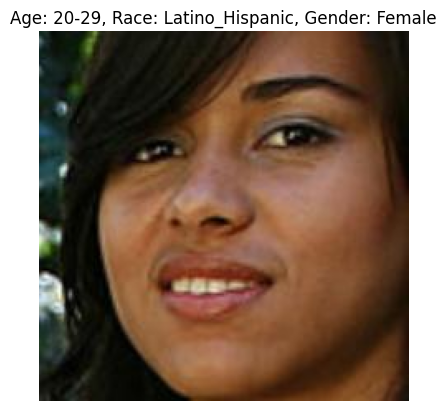

In [7]:
import matplotlib.pyplot as plt

sample = train_subset[0]
plt.imshow(sample["image"])
plt.title(f"Age: {age_names[sample['age']]}, Race: {race_names[sample['race']]}, Gender: {gender_names[sample['gender']]}")
plt.axis("off")
plt.show()

In [8]:
import pandas as pd

df = pd.DataFrame({
    "age": [age_names[i] for i in train_subset["age"]],
    "race": [race_names[i] for i in train_subset["race"]],
    "gender": [gender_names[i] for i in train_subset["gender"]],
})

print(df.shape)
df.head()

(20000, 3)


,age,race,gender
0,20-29,Latino_Hispanic,Female
1,0-2,Indian,Male
2,10-19,Middle Eastern,Male
3,20-29,Black,Female
4,20-29,White,Male


## Age distribution graph

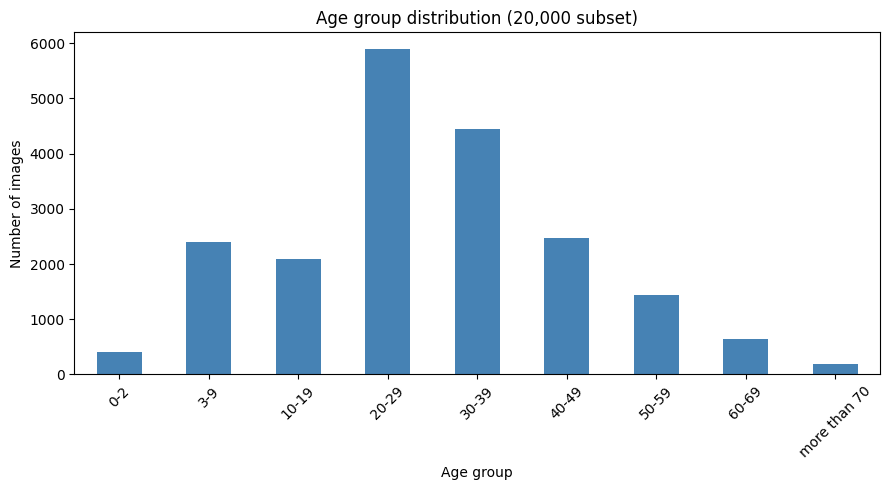

In [9]:
import matplotlib.pyplot as plt

age_order = age_names

plt.figure(figsize=(9, 5))
df["age"].value_counts().reindex(age_order).plot(kind="bar", color="steelblue")
plt.title("Age group distribution (20,000 subset)")
plt.xlabel("Age group")
plt.ylabel("Number of images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Race and Gender graph

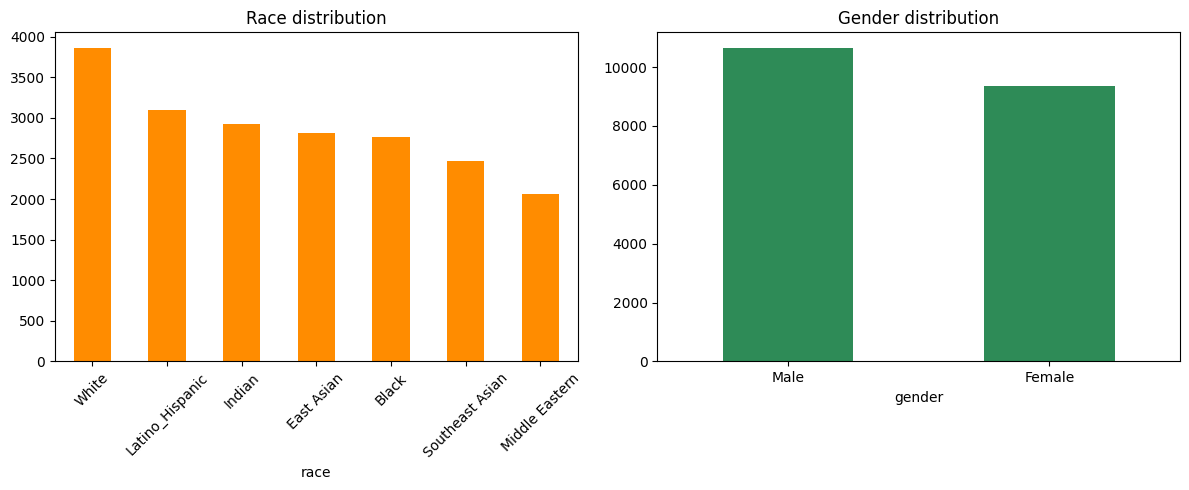

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df["race"].value_counts().plot(kind="bar", ax=axes[0], color="darkorange")
axes[0].set_title("Race distribution")
axes[0].tick_params(axis="x", rotation=45)

df["gender"].value_counts().plot(kind="bar", ax=axes[1], color="seagreen")
axes[1].set_title("Gender distribution")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

# Race vs Age heatmap

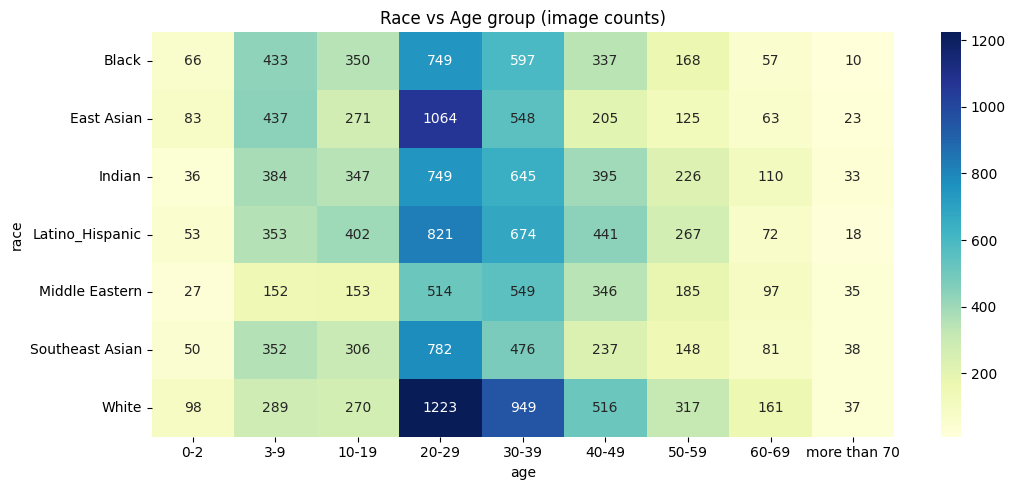

In [11]:
import seaborn as sns

table = pd.crosstab(df["race"], df["age"])[age_order]

plt.figure(figsize=(11, 5))
sns.heatmap(table, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Race vs Age group (image counts)")
plt.tight_layout()
plt.show()

Photos examples

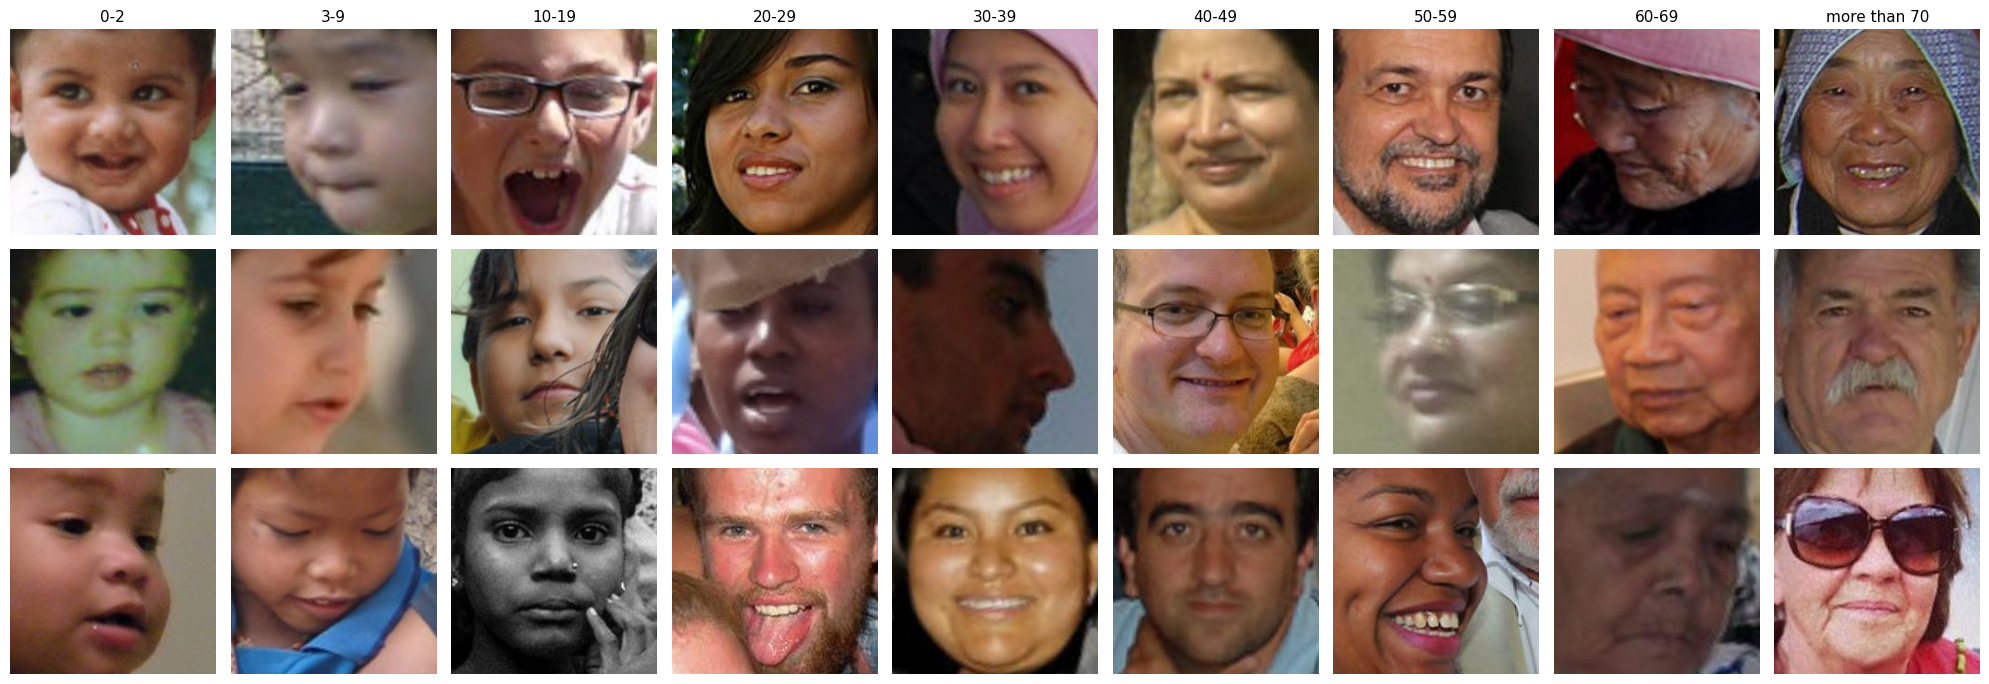

In [12]:
import numpy as np

fig, axes = plt.subplots(3, 9, figsize=(20, 7))

for col, age_idx in enumerate(range(9)):
    idxs = [i for i, a in enumerate(train_subset["age"]) if a == age_idx][:3]
    for row, i in enumerate(idxs):
        axes[row, col].imshow(train_subset[i]["image"])
        axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(age_names[age_idx], fontsize=11)

plt.tight_layout()
plt.show()

# Missing / noisy data check

In [13]:
print("Missing values:")
print(df.isnull().sum())

print("\nImage sizes (first 5):")
for i in range(5):
    print(train_subset[i]["image"].size)

Missing values:
age       0
race      0
gender    0
dtype: int64

Image sizes (first 5):
(224, 224)
(224, 224)
(224, 224)
(224, 224)
(224, 224)


Make Split

In [14]:
split = train_subset.train_test_split(
    test_size=0.15,
    stratify_by_column="age",
    seed=SEED
)

train_data = split["train"]   # learn to model
val_data = split["test"]      # for tuning
test_data = test_ds           # official validation set = final test

print("Train:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))

Train: 17000
Validation: 3000
Test: 10954


Resize, normalize and augmentation

In [15]:
from torchvision import transforms

IMG_SIZE = 128

# For Training: with augmentation
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

# For Validation / Test : augmentation NA ( only resize + normalize)
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

PyTorch Dataset class

In [16]:
import torch
from torch.utils.data import Dataset, DataLoader

class FairFaceDataset(Dataset):
    def __init__(self, hf_dataset, transform):
        self.data = hf_dataset
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]
        image = item["image"].convert("RGB")
        image = self.transform(image)
        return image, item["age"], item["race"], item["gender"]

train_dataset = FairFaceDataset(train_data, train_transform)
val_dataset = FairFaceDataset(val_data, eval_transform)
test_dataset = FairFaceDataset(test_data, eval_transform)

print("Datasets ready!")

Datasets ready!


Make the DataLoaders

In [17]:
BATCH_SIZE = 64

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

images, ages, races, genders = next(iter(train_loader))
print("Images shape:", images.shape)
print("Ages:", ages[:8])

Images shape: torch.Size([64, 3, 128, 128])
Ages: tensor([3, 5, 3, 4, 3, 6, 3, 5])


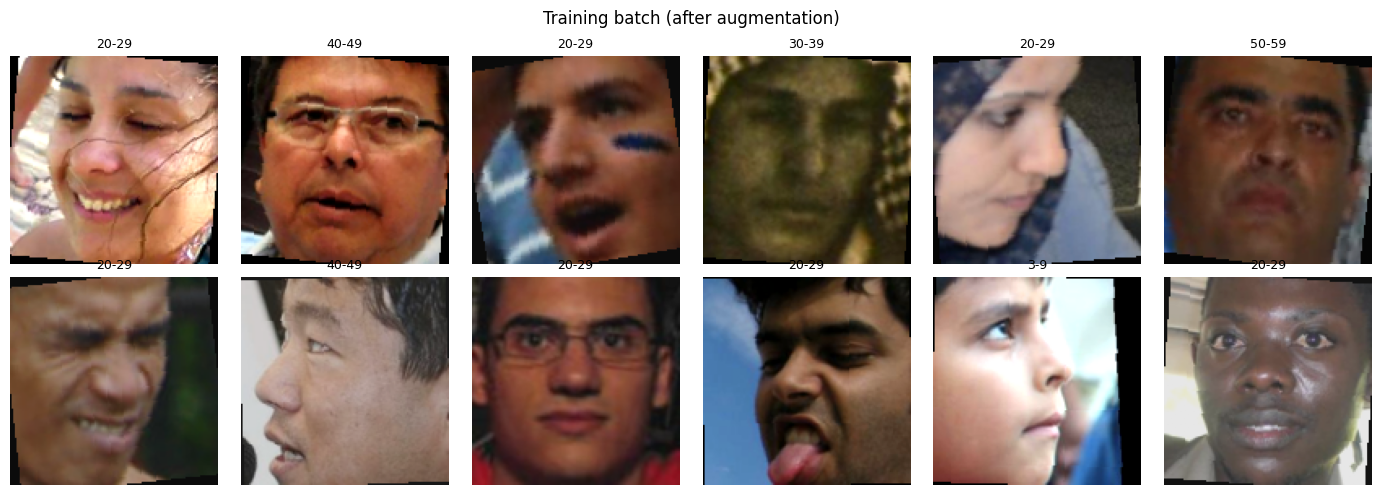

In [18]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 6, figsize=(14, 5))

for i, ax in enumerate(axes.flat):
    img = images[i] * 0.5 + 0.5     # normalize reverse,can see the photo
    ax.imshow(img.permute(1, 2, 0).clamp(0, 1))
    ax.set_title(age_names[ages[i]], fontsize=9)
    ax.axis("off")

plt.suptitle("Training batch (after augmentation)")
plt.tight_layout()
plt.show()

select the GPU

In [19]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


# Make the CNN model

In [20]:
class AgeCNN(nn.Module):
    def __init__(self, num_classes=9):
        super().__init__()

        def block(in_ch, out_ch):
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(),
                nn.MaxPool2d(2),
            )

        self.features = nn.Sequential(
            block(3, 32),     # 128 -> 64
            block(32, 64),    # 64 -> 32
            block(64, 128),   # 32 -> 16
            block(128, 256),  # 16 -> 8
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x)

model = AgeCNN().to(device)
print(model)
print("Total parameters:", sum(p.numel() for p in model.parameters()))

AgeCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (3): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3, 3),

Test the Model for correctly working

In [21]:
dummy = torch.randn(4, 3, 128, 128).to(device)
out = model(dummy)
print("Output shape:", out.shape)

Output shape: torch.Size([4, 9])


# Loss, optimizer saha Drive path

In [22]:
import os, json

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

CKPT_DIR = "/content/drive/MyDrive/fairvision"
LAST_CKPT = f"{CKPT_DIR}/baseline_last.pt"
BEST_CKPT = f"{CKPT_DIR}/baseline_best.pt"
HISTORY_FILE = f"{CKPT_DIR}/baseline_history.json"

EPOCHS = 25

# Training (with checkpoint and resume)

In [25]:
start_epoch = 0
best_val_acc = 0.0
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

if os.path.exists(LAST_CKPT):
    ckpt = torch.load(LAST_CKPT, map_location=device)
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    start_epoch = ckpt["epoch"] + 1
    best_val_acc = ckpt["best_val_acc"]
    with open(HISTORY_FILE) as f:
        history = json.load(f)
    print(f"Resuming from epoch {start_epoch}")

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for images, ages, races, genders in loader:
            images, ages = images.to(device), ages.to(device)
            outputs = model(images)
            loss = criterion(outputs, ages)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == ages).sum().item()
            total += images.size(0)
    return total_loss / total, correct / total

for epoch in range(start_epoch, EPOCHS):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)

    history["train_loss"].append(tr_loss)
    history["train_acc"].append(tr_acc)
    history["val_loss"].append(va_loss)
    history["val_acc"].append(va_acc)

    print(f"Epoch {epoch+1}/{EPOCHS} | "
          f"Train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
          f"Val loss {va_loss:.3f} acc {va_acc:.3f}")

    # Save the Best model
    if va_acc > best_val_acc:
        best_val_acc = va_acc
        torch.save(model.state_dict(), BEST_CKPT)

    # Save the all epoch checkpoint
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_val_acc": best_val_acc,
    }, LAST_CKPT)
    with open(HISTORY_FILE, "w") as f:
        json.dump(history, f)

print("Ended Training! Best val acc:", best_val_acc)

Epoch 1/25 | Train loss 1.866 acc 0.291 | Val loss 1.847 acc 0.295
Epoch 2/25 | Train loss 1.854 acc 0.294 | Val loss 1.822 acc 0.294
Epoch 3/25 | Train loss 1.827 acc 0.299 | Val loss 1.798 acc 0.302
Epoch 4/25 | Train loss 1.798 acc 0.305 | Val loss 1.799 acc 0.297
Epoch 5/25 | Train loss 1.761 acc 0.315 | Val loss 1.734 acc 0.313
Epoch 6/25 | Train loss 1.721 acc 0.326 | Val loss 1.729 acc 0.321
Epoch 7/25 | Train loss 1.677 acc 0.335 | Val loss 1.713 acc 0.336
Epoch 8/25 | Train loss 1.643 acc 0.343 | Val loss 1.599 acc 0.355
Epoch 9/25 | Train loss 1.618 acc 0.352 | Val loss 1.574 acc 0.367
Epoch 10/25 | Train loss 1.593 acc 0.356 | Val loss 1.541 acc 0.374
Epoch 11/25 | Train loss 1.570 acc 0.369 | Val loss 1.577 acc 0.385
Epoch 12/25 | Train loss 1.552 acc 0.371 | Val loss 1.541 acc 0.376
Epoch 13/25 | Train loss 1.538 acc 0.374 | Val loss 1.495 acc 0.395
Epoch 14/25 | Train loss 1.524 acc 0.378 | Val loss 1.620 acc 0.355
Epoch 15/25 | Train loss 1.511 acc 0.386 | Val loss 1.466

Training curves graph

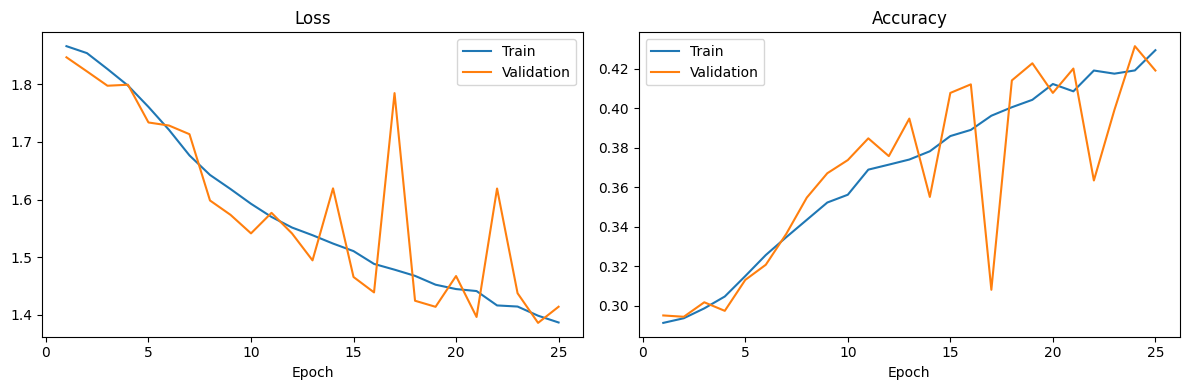

In [26]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs_range = range(1, len(history["train_loss"]) + 1)

axes[0].plot(epochs_range, history["train_loss"], label="Train")
axes[0].plot(epochs_range, history["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(epochs_range, history["train_acc"], label="Train")
axes[1].plot(epochs_range, history["val_acc"], label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

# Load the Best model

In [27]:
model.load_state_dict(torch.load(BEST_CKPT, map_location=device))
model.eval()
print("Best model loaded!")

Best model loaded!


Take the Test set predictions

In [28]:
import numpy as np

all_preds, all_true, all_race, all_gender = [], [], [], []

with torch.no_grad():
    for images, ages, races, genders in test_loader:
        images = images.to(device)
        outputs = model(images)
        preds = outputs.argmax(1).cpu()
        all_preds.extend(preds.tolist())
        all_true.extend(ages.tolist())
        all_race.extend(races.tolist())
        all_gender.extend(genders.tolist())

all_preds = np.array(all_preds)
all_true = np.array(all_true)
all_race = np.array(all_race)
all_gender = np.array(all_gender)

print("Predictions ready:", len(all_preds))

Predictions ready: 10954


# Overall accuracy

In [29]:
test_acc = (all_preds == all_true).mean()
print(f"Baseline test accuracy: {test_acc:.4f} ({test_acc*100:.1f}%)")

Baseline test accuracy: 0.4320 (43.2%)


# Precision, Recall, F1

In [30]:
from sklearn.metrics import classification_report

print(classification_report(all_true, all_preds, target_names=age_names, digits=3))

              precision    recall  f1-score   support

         0-2      0.789     0.226     0.352       199
         3-9      0.713     0.579     0.639      1356
       10-19      0.396     0.016     0.031      1181
       20-29      0.433     0.848     0.574      3300
       30-39      0.326     0.266     0.293      2330
       40-49      0.320     0.146     0.200      1353
       50-59      0.343     0.253     0.291       796
       60-69      0.346     0.206     0.258       321
more than 70      0.000     0.000     0.000       118

    accuracy                          0.432     10954
   macro avg      0.407     0.282     0.293     10954
weighted avg      0.420     0.432     0.377     10954



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# Confusion matrix

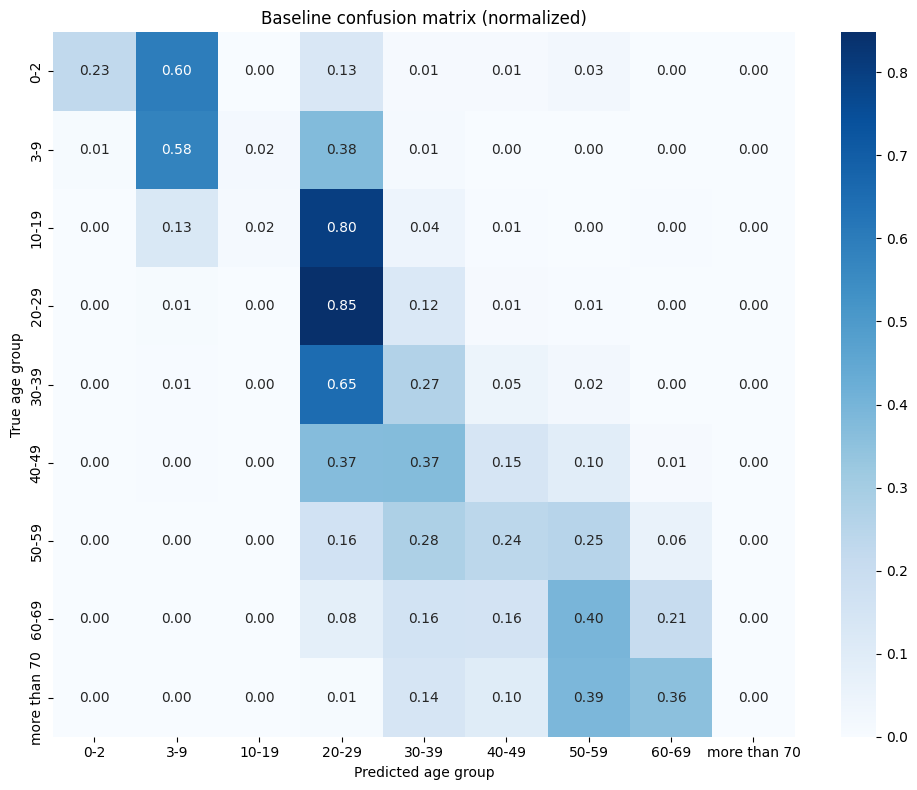

In [31]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(all_true, all_preds)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=age_names, yticklabels=age_names)
plt.xlabel("Predicted age group")
plt.ylabel("True age group")
plt.title("Baseline confusion matrix (normalized)")
plt.tight_layout()
plt.show()

Class accuracy

              accuracy
0-2              0.226
3-9              0.579
10-19            0.016
20-29            0.848
30-39            0.266
40-49            0.146
50-59            0.253
60-69            0.206
more than 70     0.000


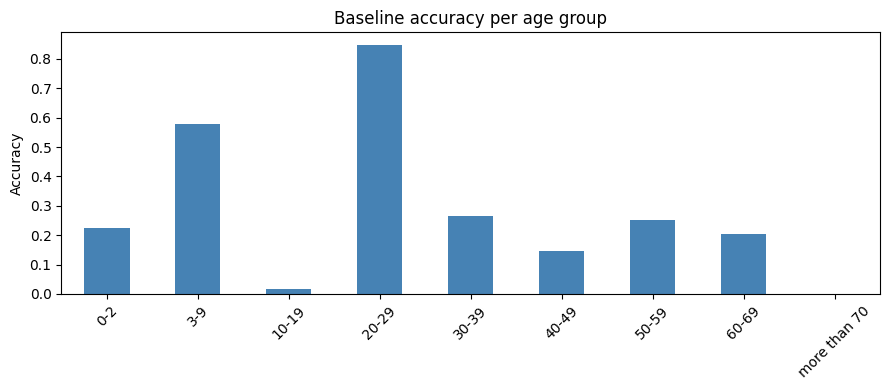

In [32]:
class_acc = {}
for i, name in enumerate(age_names):
    mask = all_true == i
    class_acc[name] = (all_preds[mask] == all_true[mask]).mean()

class_acc_df = pd.Series(class_acc).rename("accuracy").to_frame()
print(class_acc_df.round(3))

class_acc_df.plot(kind="bar", legend=False, color="steelblue", figsize=(9, 4))
plt.title("Baseline accuracy per age group")
plt.ylabel("Accuracy")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Save into Predictions Drive

In [33]:
results_df = pd.DataFrame({
    "true_age": all_true,
    "pred_age": all_preds,
    "race": all_race,
    "gender": all_gender,
})
results_df.to_csv(f"{CKPT_DIR}/baseline_test_predictions.csv", index=False)
print("Saved!")
results_df.head()

Saved!


,true_age,pred_age,race,gender
0,1,1,0,0
1,6,3,0,1
2,4,3,3,0
3,3,3,5,1
4,3,4,6,0


In [34]:
from sklearn.metrics import f1_score

race_names = train_ds.features["race"].names
gender_names = train_ds.features["gender"].names

def group_report(group_array, names):
    rows = []
    for i, name in enumerate(names):
        mask = group_array == i
        acc = (all_preds[mask] == all_true[mask]).mean()
        f1 = f1_score(all_true[mask], all_preds[mask], average="macro", zero_division=0)
        rows.append({
            "group": name,
            "n_images": int(mask.sum()),
            "accuracy": acc,
            "error_rate": 1 - acc,
            "macro_F1": f1,
        })
    return pd.DataFrame(rows).set_index("group")

Race fairness table

In [35]:
race_df = group_report(all_race, race_names)
print(race_df.round(3))

best = race_df["accuracy"].idxmax()
worst = race_df["accuracy"].idxmin()
gap = race_df["accuracy"].max() - race_df["accuracy"].min()

print(f"\nBest group  : {best} ({race_df.loc[best, 'accuracy']:.3f})")
print(f"Worst group : {worst} ({race_df.loc[worst, 'accuracy']:.3f})")
print(f"Gap (best - worst): {gap:.3f}")

                 n_images  accuracy  error_rate  macro_F1
group                                                    
East Asian           1550     0.533       0.467     0.306
Indian               1516     0.390       0.610     0.256
Black                1556     0.395       0.605     0.259
White                2085     0.424       0.576     0.295
Middle Eastern       1209     0.433       0.567     0.321
Latino_Hispanic      1623     0.397       0.603     0.277
Southeast Asian      1415     0.459       0.541     0.278

Best group  : East Asian (0.533)
Worst group : Indian (0.390)
Gap (best - worst): 0.143


Gender fairness table

In [36]:
gender_df = group_report(all_gender, gender_names)
print(gender_df.round(3))

best_g = gender_df["accuracy"].idxmax()
worst_g = gender_df["accuracy"].idxmin()
gap_g = gender_df["accuracy"].max() - gender_df["accuracy"].min()

print(f"\nBest group  : {best_g} ({gender_df.loc[best_g, 'accuracy']:.3f})")
print(f"Worst group : {worst_g} ({gender_df.loc[worst_g, 'accuracy']:.3f})")
print(f"Gap (best - worst): {gap_g:.3f}")

        n_images  accuracy  error_rate  macro_F1
group                                           
Male        5792     0.412       0.588     0.305
Female      5162     0.455       0.545     0.264

Best group  : Female (0.455)
Worst group : Male (0.412)
Gap (best - worst): 0.043


Graph(for report)

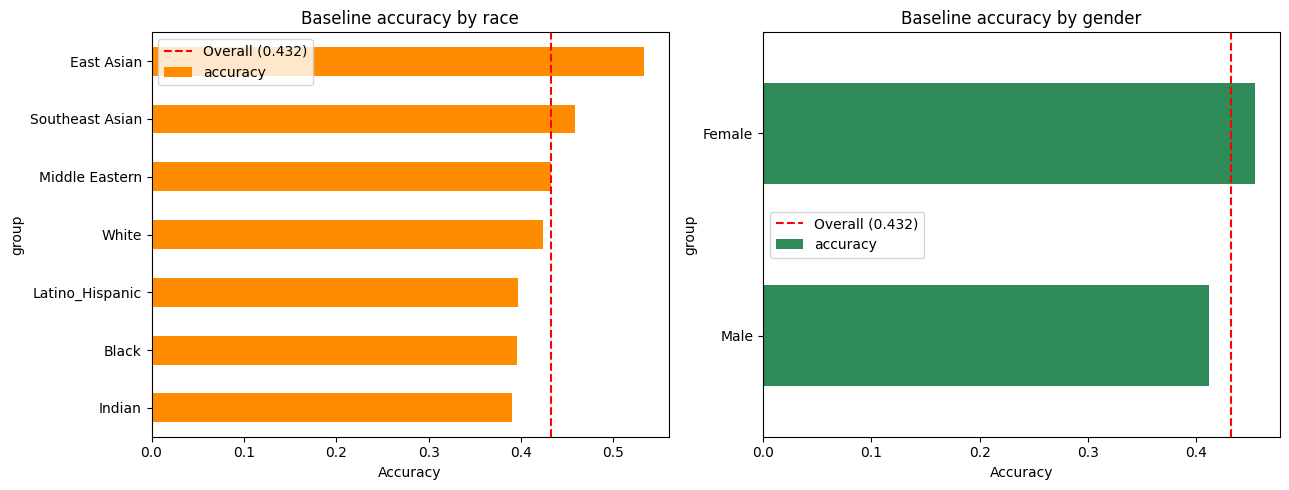

In [37]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

race_df["accuracy"].sort_values().plot(kind="barh", ax=axes[0], color="darkorange")
axes[0].axvline(test_acc, color="red", linestyle="--", label=f"Overall ({test_acc:.3f})")
axes[0].set_title("Baseline accuracy by race")
axes[0].set_xlabel("Accuracy")
axes[0].legend()

gender_df["accuracy"].sort_values().plot(kind="barh", ax=axes[1], color="seagreen")
axes[1].axvline(test_acc, color="red", linestyle="--", label=f"Overall ({test_acc:.3f})")
axes[1].set_title("Baseline accuracy by gender")
axes[1].set_xlabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

Race vs Gender

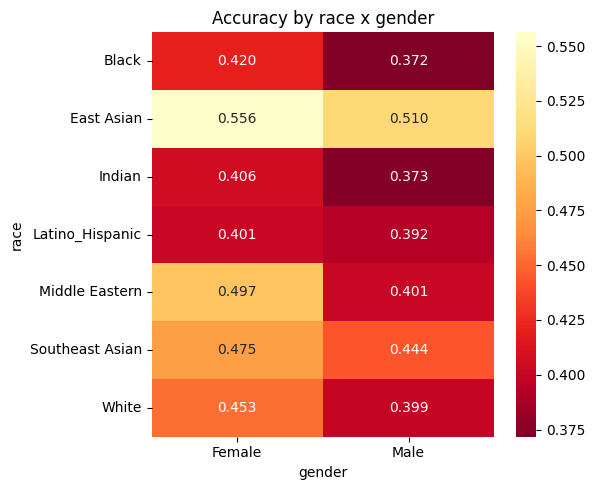

Worst intersectional group: Black Male 0.372


In [38]:
import seaborn as sns

rows = []
for r_i, r_name in enumerate(race_names):
    for g_i, g_name in enumerate(gender_names):
        mask = (all_race == r_i) & (all_gender == g_i)
        acc = (all_preds[mask] == all_true[mask]).mean()
        rows.append({"race": r_name, "gender": g_name, "accuracy": acc, "n": int(mask.sum())})

inter_df = pd.DataFrame(rows)
pivot = inter_df.pivot(index="race", columns="gender", values="accuracy")

plt.figure(figsize=(6, 5))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlOrRd_r")
plt.title("Accuracy by race x gender")
plt.tight_layout()
plt.show()

worst_row = inter_df.loc[inter_df["accuracy"].idxmin()]
print("Worst intersectional group:", worst_row["race"], worst_row["gender"], round(worst_row["accuracy"], 3))

Save the table into the Drive

In [39]:
race_df.to_csv(f"{CKPT_DIR}/baseline_race_fairness.csv")
gender_df.to_csv(f"{CKPT_DIR}/baseline_gender_fairness.csv")
inter_df.to_csv(f"{CKPT_DIR}/baseline_intersectional_fairness.csv", index=False)
print("Saved!")

Saved!


Helper functions

In [40]:
import copy

def make_model():
    torch.manual_seed(SEED)
    return AgeCNN().to(device)

def train_model(name, loader, criterion, epochs=EPOCHS):
    model = make_model()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    val_criterion = nn.CrossEntropyLoss()

    last_path = f"{CKPT_DIR}/{name}_last.pt"
    best_path = f"{CKPT_DIR}/{name}_best.pt"
    hist_path = f"{CKPT_DIR}/{name}_history.json"

    start_epoch, best_val_acc = 0, 0.0
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    if os.path.exists(last_path):
        ckpt = torch.load(last_path, map_location=device)
        model.load_state_dict(ckpt["model_state_dict"])
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
        start_epoch = ckpt["epoch"] + 1
        best_val_acc = ckpt["best_val_acc"]
        with open(hist_path) as f:
            history = json.load(f)
        print(f"[{name}] Resuming from epoch {start_epoch}")

    for epoch in range(start_epoch, epochs):
        # ---- train ----
        model.train()
        tl, tc, tn = 0.0, 0, 0
        for images, ages, races, genders in loader:
            images, ages = images.to(device), ages.to(device)
            out = model(images)
            loss = criterion(out, ages)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            tl += loss.item() * images.size(0)
            tc += (out.argmax(1) == ages).sum().item()
            tn += images.size(0)

        # ---- validation ----
        model.eval()
        vl, vc, vn = 0.0, 0, 0
        with torch.no_grad():
            for images, ages, races, genders in val_loader:
                images, ages = images.to(device), ages.to(device)
                out = model(images)
                vl += val_criterion(out, ages).item() * images.size(0)
                vc += (out.argmax(1) == ages).sum().item()
                vn += images.size(0)

        history["train_loss"].append(tl / tn)
        history["train_acc"].append(tc / tn)
        history["val_loss"].append(vl / vn)
        history["val_acc"].append(vc / vn)
        print(f"[{name}] Epoch {epoch+1}/{epochs} | "
              f"Train loss {tl/tn:.3f} acc {tc/tn:.3f} | Val loss {vl/vn:.3f} acc {vc/vn:.3f}")

        if vc / vn > best_val_acc:
            best_val_acc = vc / vn
            torch.save(model.state_dict(), best_path)

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_acc": best_val_acc,
        }, last_path)
        with open(hist_path, "w") as f:
            json.dump(history, f)

    model.load_state_dict(torch.load(best_path, map_location=device))
    print(f"[{name}] Done! Best val acc: {best_val_acc:.4f}")
    return model, history


def get_predictions(model):
    model.eval()
    preds = []
    with torch.no_grad():
        for images, ages, races, genders in test_loader:
            out = model(images.to(device))
            preds.extend(out.argmax(1).cpu().tolist())
    return np.array(preds)


def group_report_v2(preds, group_array, names):
    rows = []
    for i, nm in enumerate(names):
        mask = group_array == i
        acc = (preds[mask] == all_true[mask]).mean()
        f1 = f1_score(all_true[mask], preds[mask], average="macro", zero_division=0)
        rows.append({"group": nm, "n_images": int(mask.sum()),
                     "accuracy": acc, "error_rate": 1 - acc, "macro_F1": f1})
    return pd.DataFrame(rows).set_index("group")


def evaluate_model(name, preds):
    overall_acc = (preds == all_true).mean()
    overall_f1 = f1_score(all_true, preds, average="macro", zero_division=0)
    r_df = group_report_v2(preds, all_race, race_names)
    g_df = group_report_v2(preds, all_gender, gender_names)

    print(f"===== {name} =====")
    print(f"Overall accuracy : {overall_acc:.3f}")
    print(f"Overall macro F1 : {overall_f1:.3f}")
    print("\nRace:")
    print(r_df.round(3))
    print(f"Race worst group : {r_df['accuracy'].idxmin()} ({r_df['accuracy'].min():.3f})")
    print(f"Race gap         : {r_df['accuracy'].max() - r_df['accuracy'].min():.3f}")
    print("\nGender:")
    print(g_df.round(3))
    print(f"Gender gap       : {g_df['accuracy'].max() - g_df['accuracy'].min():.3f}")

    # save to the Drive
    pd.DataFrame({"true_age": all_true, "pred_age": preds,
                  "race": all_race, "gender": all_gender}
                 ).to_csv(f"{CKPT_DIR}/{name}_test_predictions.csv", index=False)
    return r_df, g_df

print("Helpers ready!")

Helpers ready!


# Class-weighted loss

Make the Class weights

In [41]:
age_counts = np.bincount(np.array(train_data["age"]), minlength=9)
weights = len(train_data) / (9 * age_counts)

class_weights = torch.tensor(weights, dtype=torch.float).to(device)

for name, c, w in zip(age_names, age_counts, weights):
    print(f"{name:>13} | images: {c:5d} | weight: {w:.2f}")

          0-2 | images:   351 | weight: 5.38
          3-9 | images:  2040 | weight: 0.93
        10-19 | images:  1784 | weight: 1.06
        20-29 | images:  5017 | weight: 0.38
        30-39 | images:  3772 | weight: 0.50
        40-49 | images:  2105 | weight: 0.90
        50-59 | images:  1221 | weight: 1.55
        60-69 | images:   545 | weight: 3.47
 more than 70 | images:   165 | weight: 11.45


Train the Model

In [42]:
weighted_criterion = nn.CrossEntropyLoss(weight=class_weights)

model_w, hist_w = train_model("mit_classweight", train_loader, weighted_criterion)

[mit_classweight] Epoch 1/25 | Train loss 2.193 acc 0.124 | Val loss 2.134 acc 0.146
[mit_classweight] Epoch 2/25 | Train loss 2.176 acc 0.135 | Val loss 2.177 acc 0.141
[mit_classweight] Epoch 3/25 | Train loss 2.167 acc 0.150 | Val loss 2.097 acc 0.136
[mit_classweight] Epoch 4/25 | Train loss 2.162 acc 0.136 | Val loss 2.201 acc 0.117
[mit_classweight] Epoch 5/25 | Train loss 2.134 acc 0.149 | Val loss 2.057 acc 0.176
[mit_classweight] Epoch 6/25 | Train loss 2.105 acc 0.162 | Val loss 2.073 acc 0.129
[mit_classweight] Epoch 7/25 | Train loss 2.055 acc 0.163 | Val loss 1.986 acc 0.251
[mit_classweight] Epoch 8/25 | Train loss 2.028 acc 0.176 | Val loss 2.087 acc 0.174
[mit_classweight] Epoch 9/25 | Train loss 1.976 acc 0.182 | Val loss 2.029 acc 0.153
[mit_classweight] Epoch 10/25 | Train loss 1.947 acc 0.199 | Val loss 1.959 acc 0.207
[mit_classweight] Epoch 11/25 | Train loss 1.930 acc 0.194 | Val loss 2.467 acc 0.118
[mit_classweight] Epoch 12/25 | Train loss 1.877 acc 0.199 | Va

Evaluate

In [43]:
preds_w = get_predictions(model_w)
race_w, gender_w = evaluate_model("mit_classweight", preds_w)

===== mit_classweight =====
Overall accuracy : 0.335
Overall macro F1 : 0.295

Race:
                 n_images  accuracy  error_rate  macro_F1
group                                                    
East Asian           1550     0.375       0.625     0.276
Indian               1516     0.334       0.666     0.303
Black                1556     0.296       0.704     0.242
White                2085     0.325       0.675     0.298
Middle Eastern       1209     0.340       0.660     0.288
Latino_Hispanic      1623     0.346       0.654     0.271
Southeast Asian      1415     0.335       0.665     0.283
Race worst group : Black (0.296)
Race gap         : 0.079

Gender:
        n_images  accuracy  error_rate  macro_F1
group                                           
Male        5792     0.322       0.678     0.299
Female      5162     0.350       0.650     0.276
Gender gap       : 0.028


# Oversampling (balanced sampler)

Make the Sampler

In [44]:
from torch.utils.data import WeightedRandomSampler

ages_tr = np.array(train_data["age"])
races_tr = np.array(train_data["race"])

cell_ids = races_tr * 9 + ages_tr
cell_counts = np.bincount(cell_ids, minlength=63)

sample_weights = 1.0 / cell_counts[cell_ids]

sampler = WeightedRandomSampler(
    weights=torch.tensor(sample_weights, dtype=torch.double),
    num_samples=len(train_data),
    replacement=True
)

balanced_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                             sampler=sampler, num_workers=2)

_, ages_b, _, _ = next(iter(balanced_loader))
print("Age counts in one balanced batch:", np.bincount(ages_b.numpy(), minlength=9))

Age counts in one balanced batch: [12  4  7  8  3 10  3  8  9]


Train the Model

In [45]:
plain_criterion = nn.CrossEntropyLoss()

model_s, hist_s = train_model("mit_oversample", balanced_loader, plain_criterion)

[mit_oversample] Epoch 1/25 | Train loss 2.133 acc 0.173 | Val loss 2.108 acc 0.131
[mit_oversample] Epoch 2/25 | Train loss 1.975 acc 0.237 | Val loss 1.965 acc 0.206
[mit_oversample] Epoch 3/25 | Train loss 1.860 acc 0.273 | Val loss 1.954 acc 0.168
[mit_oversample] Epoch 4/25 | Train loss 1.775 acc 0.301 | Val loss 1.949 acc 0.224
[mit_oversample] Epoch 5/25 | Train loss 1.722 acc 0.319 | Val loss 1.976 acc 0.184
[mit_oversample] Epoch 6/25 | Train loss 1.674 acc 0.328 | Val loss 1.664 acc 0.308
[mit_oversample] Epoch 7/25 | Train loss 1.641 acc 0.341 | Val loss 1.806 acc 0.226
[mit_oversample] Epoch 8/25 | Train loss 1.610 acc 0.349 | Val loss 1.804 acc 0.229
[mit_oversample] Epoch 9/25 | Train loss 1.581 acc 0.366 | Val loss 1.838 acc 0.218
[mit_oversample] Epoch 10/25 | Train loss 1.572 acc 0.366 | Val loss 1.662 acc 0.245
[mit_oversample] Epoch 11/25 | Train loss 1.543 acc 0.377 | Val loss 1.676 acc 0.307
[mit_oversample] Epoch 12/25 | Train loss 1.515 acc 0.384 | Val loss 1.583

Evaluate

In [46]:
preds_s = get_predictions(model_s)
race_s, gender_s = evaluate_model("mit_oversample", preds_s)

===== mit_oversample =====
Overall accuracy : 0.392
Overall macro F1 : 0.362

Race:
                 n_images  accuracy  error_rate  macro_F1
group                                                    
East Asian           1550     0.428       0.572     0.376
Indian               1516     0.399       0.601     0.377
Black                1556     0.364       0.636     0.287
White                2085     0.385       0.615     0.356
Middle Eastern       1209     0.391       0.609     0.365
Latino_Hispanic      1623     0.376       0.624     0.345
Southeast Asian      1415     0.408       0.592     0.361
Race worst group : Black (0.364)
Race gap         : 0.063

Gender:
        n_images  accuracy  error_rate  macro_F1
group                                           
Male        5792     0.391       0.609     0.377
Female      5162     0.394       0.606     0.336
Gender gap       : 0.003


# Load the Predictions

In [47]:
model_files = {
    "Baseline": "baseline",
    "Class-weighted": "mit_classweight",
    "Oversampling": "mit_oversample",
}

preds_dict = {}
for label, key in model_files.items():
    d = pd.read_csv(f"{CKPT_DIR}/{key}_test_predictions.csv")
    preds_dict[label] = d["pred_age"].values

print("Loaded:", list(preds_dict.keys()))

Loaded: ['Baseline', 'Class-weighted', 'Oversampling']


# Summary table

In [48]:
summary_rows = []
for label, preds in preds_dict.items():
    r_df = group_report_v2(preds, all_race, race_names)
    g_df = group_report_v2(preds, all_gender, gender_names)
    summary_rows.append({
        "Model": label,
        "Overall acc": (preds == all_true).mean(),
        "Macro F1": f1_score(all_true, preds, average="macro", zero_division=0),
        "Best race acc": r_df["accuracy"].max(),
        "Worst race acc": r_df["accuracy"].min(),
        "Race gap": r_df["accuracy"].max() - r_df["accuracy"].min(),
        "Gender gap": g_df["accuracy"].max() - g_df["accuracy"].min(),
    })

summary = pd.DataFrame(summary_rows).set_index("Model")
print(summary.round(3))
summary.to_csv(f"{CKPT_DIR}/final_comparison_summary.csv")

                Overall acc  Macro F1  Best race acc  Worst race acc  \
Model                                                                  
Baseline              0.432     0.293          0.533           0.390   
Class-weighted        0.335     0.295          0.375           0.296   
Oversampling          0.392     0.362          0.428           0.364   

                Race gap  Gender gap  
Model                                 
Baseline           0.143       0.043  
Class-weighted     0.079       0.028  
Oversampling       0.063       0.003  


# Summary chart

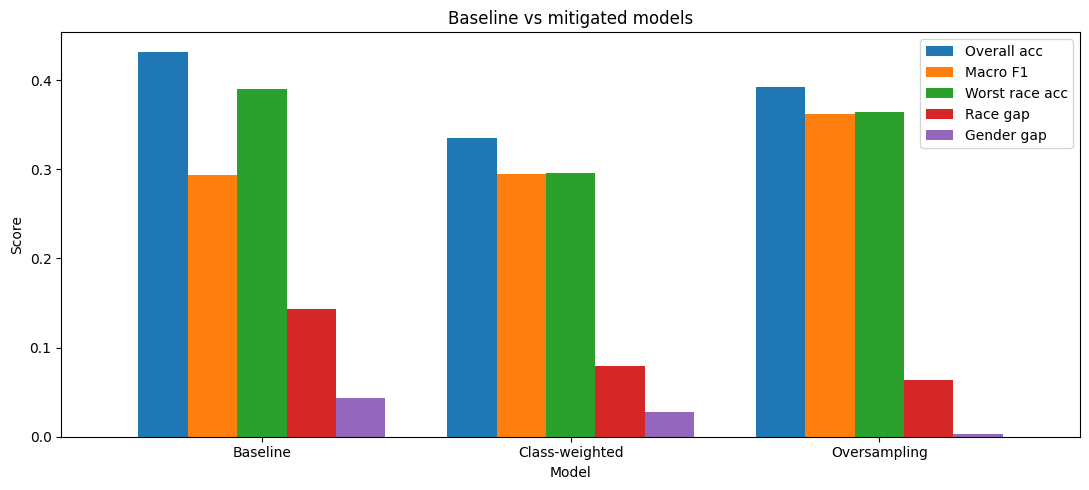

In [49]:
import matplotlib.pyplot as plt

metrics = ["Overall acc", "Macro F1", "Worst race acc", "Race gap", "Gender gap"]
summary[metrics].plot(kind="bar", figsize=(11, 5), width=0.8)
plt.title("Baseline vs mitigated models")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

Race accuracy (for 3 models)

                 Baseline  Class-weighted  Oversampling
group                                                  
East Asian          0.533           0.375         0.428
Indian              0.390           0.334         0.399
Black               0.395           0.296         0.364
White               0.424           0.325         0.385
Middle Eastern      0.433           0.340         0.391
Latino_Hispanic     0.397           0.346         0.376
Southeast Asian     0.459           0.335         0.408


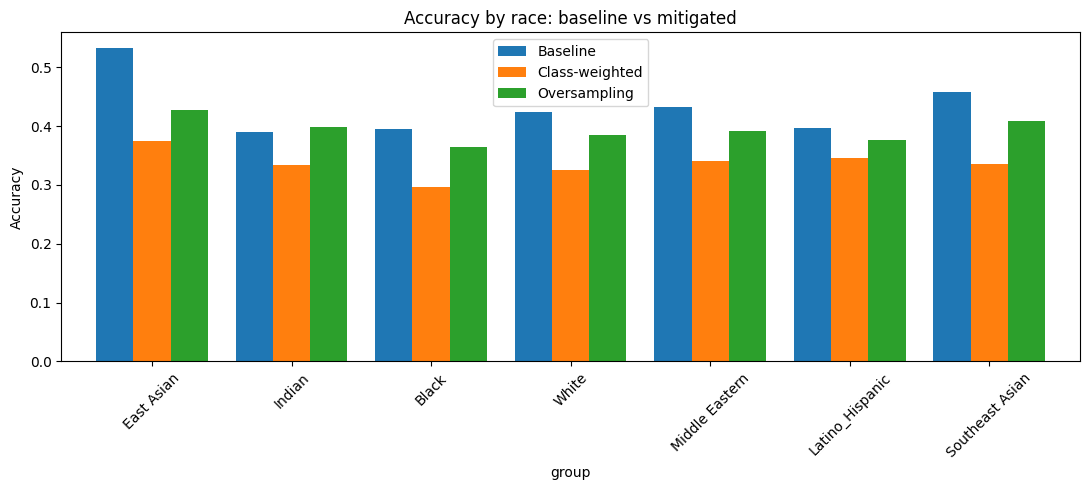

In [50]:
race_compare = pd.DataFrame({
    label: group_report_v2(preds, all_race, race_names)["accuracy"]
    for label, preds in preds_dict.items()
})
print(race_compare.round(3))

race_compare.plot(kind="bar", figsize=(11, 5), width=0.8)
plt.title("Accuracy by race: baseline vs mitigated")
plt.ylabel("Accuracy")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Gender walin accuracy

In [51]:
gender_compare = pd.DataFrame({
    label: group_report_v2(preds, all_gender, gender_names)["accuracy"]
    for label, preds in preds_dict.items()
})
print(gender_compare.round(3))

        Baseline  Class-weighted  Oversampling
group                                         
Male       0.412           0.322         0.391
Female     0.455           0.350         0.394


Age group recall

              Baseline  Class-weighted  Oversampling
0-2              0.226           0.281         0.643
3-9              0.579           0.313         0.527
10-19            0.016           0.144         0.381
20-29            0.848           0.450         0.602
30-39            0.266           0.277         0.218
40-49            0.146           0.463         0.118
50-59            0.253           0.235         0.245
60-69            0.206           0.103         0.383
more than 70     0.000           0.381         0.305


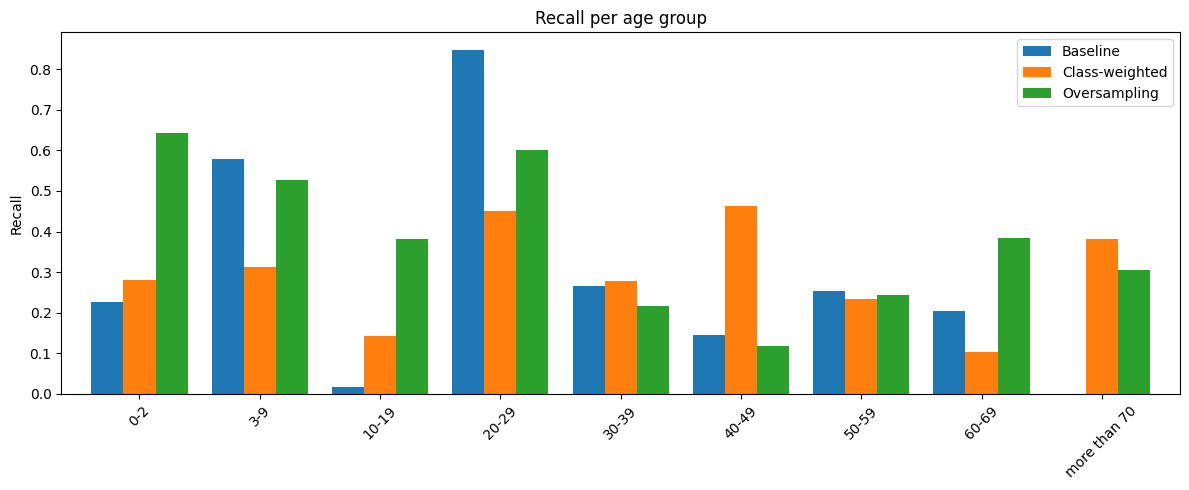

In [52]:
from sklearn.metrics import recall_score

recall_compare = pd.DataFrame({
    label: recall_score(all_true, preds, average=None, labels=list(range(9)), zero_division=0)
    for label, preds in preds_dict.items()
}, index=age_names)

print(recall_compare.round(3))

recall_compare.plot(kind="bar", figsize=(12, 5), width=0.8)
plt.title("Recall per age group")
plt.ylabel("Recall")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Worst intersectional group (race x gender) for all model

In [53]:
inter_rows = []
for label, preds in preds_dict.items():
    for r_i, r_name in enumerate(race_names):
        for g_i, g_name in enumerate(gender_names):
            mask = (all_race == r_i) & (all_gender == g_i)
            inter_rows.append({
                "Model": label, "Group": f"{r_name} {g_name}",
                "accuracy": (preds[mask] == all_true[mask]).mean(),
            })

inter_all = pd.DataFrame(inter_rows)
worst = inter_all.loc[inter_all.groupby("Model")["accuracy"].idxmin()]
print(worst.round(3).to_string(index=False))

         Model               Group  accuracy
      Baseline          Black Male     0.372
Class-weighted          Black Male     0.245
  Oversampling Middle Eastern Male     0.355


Best mitigated model confusion matrix

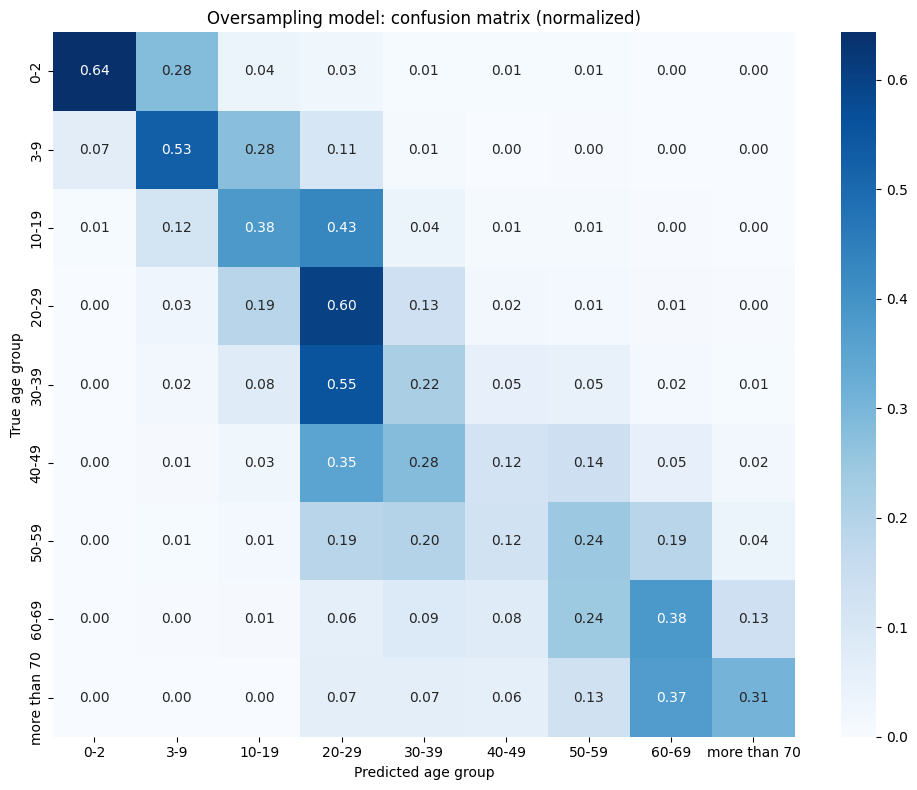

In [54]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(all_true, preds_dict["Oversampling"])
cm_norm = cm / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=age_names, yticklabels=age_names)
plt.xlabel("Predicted age group")
plt.ylabel("True age group")
plt.title("Oversampling model: confusion matrix (normalized)")
plt.tight_layout()
plt.show()

Make the Folder and copy the model

In [55]:
import shutil, os

APP_DIR = f"{CKPT_DIR}/streamlit_app"
os.makedirs(APP_DIR, exist_ok=True)

shutil.copy(f"{CKPT_DIR}/mit_oversample_best.pt", f"{APP_DIR}/mit_oversample_best.pt")
print(os.listdir(APP_DIR))

['mit_oversample_best.pt']


model.py (CNN)

In [56]:
%%writefile /content/drive/MyDrive/fairvision/streamlit_app/model.py
import torch.nn as nn

class AgeCNN(nn.Module):
    def __init__(self, num_classes=9):
        super().__init__()

        def block(in_ch, out_ch):
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(),
                nn.MaxPool2d(2),
            )

        self.features = nn.Sequential(
            block(3, 32),
            block(32, 64),
            block(64, 128),
            block(128, 256),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x)

Writing /content/drive/MyDrive/fairvision/streamlit_app/model.py


app.py (website)

In [57]:
%%writefile /content/drive/MyDrive/fairvision/streamlit_app/app.py
import streamlit as st
import torch
from torchvision import transforms
from PIL import Image
from model import AgeCNN

AGE_LABELS = ["0-2", "3-9", "10-19", "20-29", "30-39",
              "40-49", "50-59", "60-69", "70+"]

st.set_page_config(page_title="FairVision", page_icon="🧑")

@st.cache_resource
def load_model():
    model = AgeCNN()
    model.load_state_dict(torch.load("mit_oversample_best.pt", map_location="cpu"))
    model.eval()
    return model

model = load_model()

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

st.title("FairVision: Age Group Classifier")
st.write(
    "This demo uses a CNN trained from scratch in PyTorch on the FairFace dataset "
    "to predict the age group of a face image. The model was trained with "
    "race-by-age balanced oversampling to reduce demographic bias."
)

uploaded = st.file_uploader("Upload a face image", type=["jpg", "jpeg", "png"])

if uploaded is not None:
    image = Image.open(uploaded).convert("RGB")
    st.image(image, caption="Uploaded image", width=250)

    x = transform(image).unsqueeze(0)
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)[0]

    top_probs, top_idx = torch.topk(probs, 3)

    st.subheader("Top 3 predictions")
    for p, i in zip(top_probs, top_idx):
        st.write(f"**{AGE_LABELS[i]}**: {p.item() * 100:.1f}%")
        st.progress(float(p))

st.markdown("---")
st.subheader("Limitations and responsible use")
st.write(
    "- Overall test accuracy is about 39%, so predictions can be wrong, "
    "especially between neighbouring age groups.\n"
    "- Performance still differs across race and gender groups.\n"
    "- Trained on a 20,000-image subset of FairFace with limited training.\n"
    "- This is an educational prototype. Do not use it for identity, security, "
    "hiring, or any decision that affects people."
)

Writing /content/drive/MyDrive/fairvision/streamlit_app/app.py


requirements.txt

In [58]:
%%writefile /content/drive/MyDrive/fairvision/streamlit_app/requirements.txt
--extra-index-url https://download.pytorch.org/whl/cpu
streamlit
torch
torchvision
pillow

Writing /content/drive/MyDrive/fairvision/streamlit_app/requirements.txt


check the flies in correctly

In [59]:
print(os.listdir(APP_DIR))

['mit_oversample_best.pt', 'model.py', 'app.py', 'requirements.txt']


Make the zip file and download it

In [60]:
from google.colab import files

shutil.make_archive("/content/streamlit_app", "zip", APP_DIR)
files.download("/content/streamlit_app.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>